# 01 Data Quality

**Purpose.** Understand the raw price data before writing a single feature.

This notebook is exploration only. It reads the cached parquet files directly
and defines everything it needs inline.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.figsize": (12, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.color": "#D9E2E4",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

TEAL, AMBER, RED, GREY = "#0E7C86", "#C77700", "#C0392B", "#7A8B90"

RAW = Path("../data/01-raw")
FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

print("Setup complete.")

Setup complete.


In [2]:
files = sorted(RAW.glob("*.parquet"))
bars = {path.stem: pd.read_parquet(path) for path in files}

print(f"Loaded {len(bars)} tickers from {RAW.resolve()}")
print(f"Columns: {list(next(iter(bars.values())).columns)}")

bars["SPY"].head()

Loaded 11 tickers from C:\Users\BRAIN\Desktop\ML\stock-return-predictor\data\01-raw
Columns: ['open', 'high', 'low', 'close', 'adj_close', 'volume']


,open,high,low,close,adj_close,volume
date,,,,,,
2005-01-03,121.559998,121.760002,119.900002,120.300003,80.973503,55748000
2005-01-04,120.459999,120.540001,118.440002,118.830002,79.984085,69167600
2005-01-05,118.739998,119.250000,118.000000,118.010002,79.432121,65667300
2005-01-06,118.440002,119.150002,118.260002,118.610001,79.835960,47814700
2005-01-07,118.970001,119.230003,118.129997,118.440002,79.721581,55847700


In [3]:
coverage = pd.DataFrame({
    "bars": {t: len(d) for t, d in bars.items()},
    "first": {t: d.index[0].date() for t, d in bars.items()},
    "last": {t: d.index[-1].date() for t, d in bars.items()},
    "missing": {t: int(d.isna().sum().sum()) for t, d in bars.items()},
    "zero_volume": {t: int((d["volume"] == 0).sum()) for t, d in bars.items()},
}).sort_index()

coverage

,bars,first,last,missing,zero_volume
AAPL,5032,2005-01-03,2024-12-30,0,0
GE,5032,2005-01-03,2024-12-30,0,0
INTC,5032,2005-01-03,2024-12-30,0,0
JNJ,5032,2005-01-03,2024-12-30,0,0
JPM,5032,2005-01-03,2024-12-30,0,0
KO,5032,2005-01-03,2024-12-30,0,0
MSFT,5032,2005-01-03,2024-12-30,0,0
PG,5032,2005-01-03,2024-12-30,0,0
SPY,5032,2005-01-03,2024-12-30,0,0
WMT,5032,2005-01-03,2024-12-30,0,0


In [4]:
same_length = coverage["bars"].nunique() == 1
same_start = coverage["first"].nunique() == 1
same_end = coverage["last"].nunique() == 1

print(f"All tickers have the same bar count : {same_length}")
print(f"All tickers start on the same date  : {same_start}")
print(f"All tickers end on the same date    : {same_end}")
print(f"Total missing values across all     : {coverage['missing'].sum():,}")
print(f"Total zero-volume days              : {coverage['zero_volume'].sum():,}")

All tickers have the same bar count : True
All tickers start on the same date  : True
All tickers end on the same date    : True
Total missing values across all     : 0
Total zero-volume days              : 0


### Trading Calendar

In [5]:
spy = bars["SPY"]
per_year = spy.index.year.value_counts().sort_index()

print(f"Bars per year: min {per_year.min()}, median {per_year.median():.0f}, max {per_year.max()}")
print()
print(per_year.to_string())

Bars per year: min 250, median 252, max 253

date
2005    252
2006    251
2007    251
2008    253
2009    252
2010    252
2011    252
2012    250
2013    252
2014    252
2015    252
2016    252
2017    251
2018    251
2019    252
2020    253
2021    252
2022    251
2023    250
2024    251


In [6]:
gaps = spy.index.to_series().diff().dt.days.dropna()

print("Gaps between consecutive bars, in calendar days:")
print(gaps.value_counts().sort_index().head(8).to_string())
print()
print(f"Largest gap: {int(gaps.max())} days, starting {gaps.idxmax().date()}")

Gaps between consecutive bars, in calendar days:
date
1.0    3942
2.0      46
3.0     907
4.0     134
5.0       2

Largest gap: 5 days, starting 2007-01-03


### Checking if price have been adjusted

`close` is the price as traded. `adj_close` is that price restated for splits and
dividends, which is what any return calculation must use.

In [7]:
adjustment = pd.DataFrame([
    {
        "ticker": ticker,
        "ratio_start": round(frame["close"].iloc[0] / frame["adj_close"].iloc[0], 3),
        "ratio_end": round(frame["close"].iloc[-1] / frame["adj_close"].iloc[-1], 3),
        "identical": bool(np.allclose(frame["close"], frame["adj_close"])),
    }
    for ticker, frame in bars.items()
]).set_index("ticker").sort_index()

adjustment

,ratio_start,ratio_end,identical
ticker,,,
AAPL,1.194,1.007,False
GE,1.671,1.008,False
INTC,1.730,1.000,False
JNJ,1.851,1.047,False
JPM,1.775,1.036,False
KO,1.922,1.049,False
MSFT,1.461,1.014,False
PG,1.827,1.049,False
SPY,1.486,1.020,False


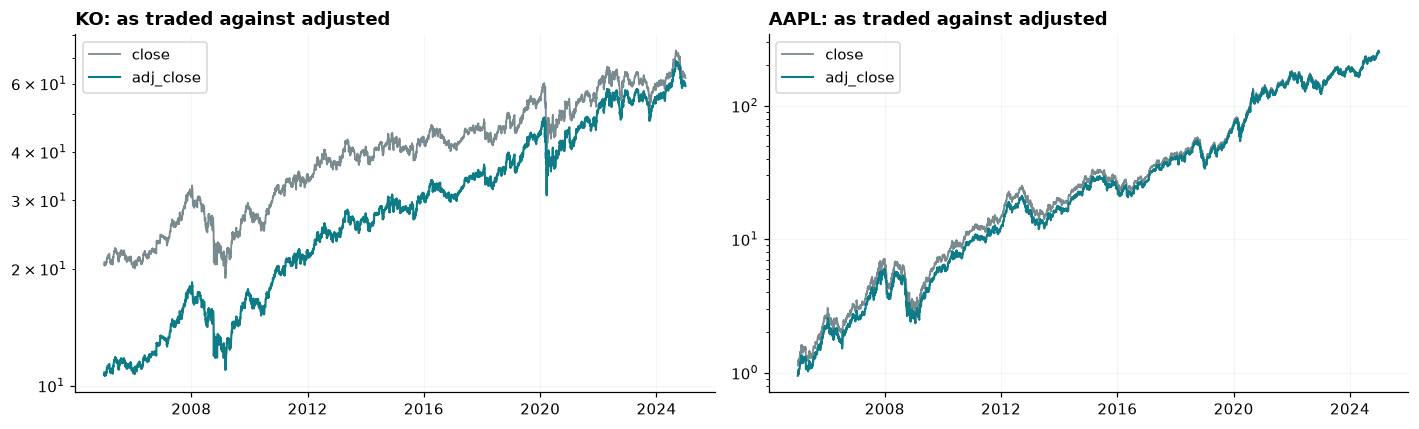

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for name, axis in zip(["KO", "AAPL"], axes):
    frame = bars[name]
    axis.plot(frame.index, frame["close"], color=GREY, lw=1.2, label="close")
    axis.plot(frame.index, frame["adj_close"], color=TEAL, lw=1.4, label="adj_close")
    axis.set_title(f"{name}: as traded against adjusted", loc="left", fontweight="bold")
    axis.set_yscale("log")
    axis.legend()

save("01_close_vs_adjusted")
plt.show()

### SPlits, Checked against known dates

In [9]:
def around(ticker, when, days=4):
    """Return the bars either side of a date, with both return series."""
    frame = bars[ticker]
    when = pd.Timestamp(when)
    window = frame.loc[when - pd.Timedelta(days=days) : when + pd.Timedelta(days=days)]

    out = window[["close", "adj_close"]].copy()
    out["close_return"] = out["close"].pct_change()
    out["adj_return"] = out["adj_close"].pct_change()

    return out.round(4)

around("AAPL", "2014-06-09")

,close,adj_close,close_return,adj_return
date,,,,
2014-06-05,23.1196,20.2570,NaN,NaN
2014-06-06,23.0561,20.2013,-0.0027,-0.0027
2014-06-09,23.4250,20.5246,0.0160,0.0160
2014-06-10,23.5625,20.6451,0.0059,0.0059
2014-06-11,23.4650,20.5596,-0.0041,-0.0041
2014-06-12,23.0725,20.2157,-0.0167,-0.0167
2014-06-13,22.8200,19.9945,-0.0109,-0.0109


In [10]:
around("AAPL", "2020-08-31")

,close,adj_close,close_return,adj_return
date,,,,
2020-08-27,125.0100,121.1519,NaN,NaN
2020-08-28,124.8075,120.9557,-0.0016,-0.0016
2020-08-31,129.0400,125.0575,0.0339,0.0339
2020-09-01,134.1800,130.0389,0.0398,0.0398
2020-09-02,131.4000,127.3447,-0.0207,-0.0207
2020-09-03,120.8800,117.1494,-0.0801,-0.0801
2020-09-04,120.9600,117.2269,0.0007,0.0007


### Daily Returns

In [11]:
returns = pd.DataFrame(
    {ticker: frame["adj_close"].pct_change() for ticker, frame in bars.items()}
).dropna(how="all")

summary = returns.describe().T[["mean", "std", "min", "max"]]
summary["ann_return"] = (1 + returns.mean()) ** 252 - 1
summary["ann_vol"] = returns.std() * np.sqrt(252)
summary["skew"] = returns.skew()
summary["kurtosis"] = returns.kurtosis()

summary.round(4)

,mean,std,min,max,ann_return,ann_vol,skew,kurtosis
AAPL,0.0013,0.0202,-0.1792,0.1390,0.3924,0.3214,-0.0230,5.3551
GE,0.0003,0.0208,-0.1516,0.1970,0.0806,0.3299,0.2514,8.9503
INTC,0.0003,0.0206,-0.2606,0.1952,0.0768,0.3275,-0.5224,12.3598
JNJ,0.0003,0.0108,-0.1004,0.1223,0.0880,0.1708,0.2317,11.7406
JPM,0.0007,0.0229,-0.2073,0.2510,0.2010,0.3639,0.9608,19.7169
KO,0.0004,0.0114,-0.0967,0.1388,0.1069,0.1813,0.0806,12.8368
MSFT,0.0008,0.0171,-0.1474,0.1860,0.2135,0.2713,0.2384,9.9309
PG,0.0004,0.0114,-0.0874,0.1201,0.1046,0.1805,0.1060,10.4379
SPY,0.0005,0.0120,-0.1094,0.1452,0.1235,0.1904,-0.0805,14.9475
WMT,0.0005,0.0126,-0.1138,0.1171,0.1299,0.2008,0.2349,12.8867


In [12]:
THRESHOLD = 0.15

# Stack first, then filter. Filtering the frame and stacking afterwards keeps
# the NaN cells and inflates the count enormously.
stacked = returns.stack()
extreme = stacked[stacked.abs() > THRESHOLD].sort_values()

print(f"Moves beyond +/-{THRESHOLD:.0%}: {len(extreme)}")
print()

if len(extreme):
    print("Largest falls:")
    print(extreme.head(10).round(4).to_string())
    print()
    print("Largest rises:")
    print(extreme.tail(10).round(4).to_string())

Moves beyond +/-15%: 21

Largest falls:
date            
2024-08-02  INTC   -0.2606
2009-01-20  JPM    -0.2073
2020-03-16  INTC   -0.1804
2008-09-29  AAPL   -0.1792
2008-11-20  JPM    -0.1788
2008-12-01  JPM    -0.1750
2020-07-24  INTC   -0.1624
2020-03-16  GE     -0.1516
2008-09-29  JPM    -0.1501
2008-07-16  JPM     0.1586

Largest rises:
date            
2008-10-13  XOM     0.1719
2020-03-13  JPM     0.1801
2008-10-13  MSFT    0.1860
2009-04-09  JPM     0.1939
2020-03-13  INTC    0.1952
2009-03-10  GE      0.1970
2008-11-24  JPM     0.2139
2009-03-10  JPM     0.2264
2009-03-23  JPM     0.2467
2009-01-21  JPM     0.2510


### Fat tails

Financial returns are not normally distributed, and assuming otherwise
understates how often large losses occur.

In [13]:
spy_returns = returns["SPY"].dropna()
z_scores = (spy_returns - spy_returns.mean()) / spy_returns.std()

beyond_3 = int((z_scores.abs() > 3).sum())
expected_3 = len(z_scores) * 0.0027

print(f"SPY days beyond 3 standard deviations : {beyond_3}")
print(f"A normal distribution would predict    : {expected_3:.0f}")
print(f"Ratio                                  : {beyond_3 / expected_3:.1f}x")
print()
print(f"Jarque-Bera p-value: {stats.jarque_bera(spy_returns).pvalue:.2e}")

SPY days beyond 3 standard deviations : 83
A normal distribution would predict    : 14
Ratio                                  : 6.1x

Jarque-Bera p-value: 0.00e+00


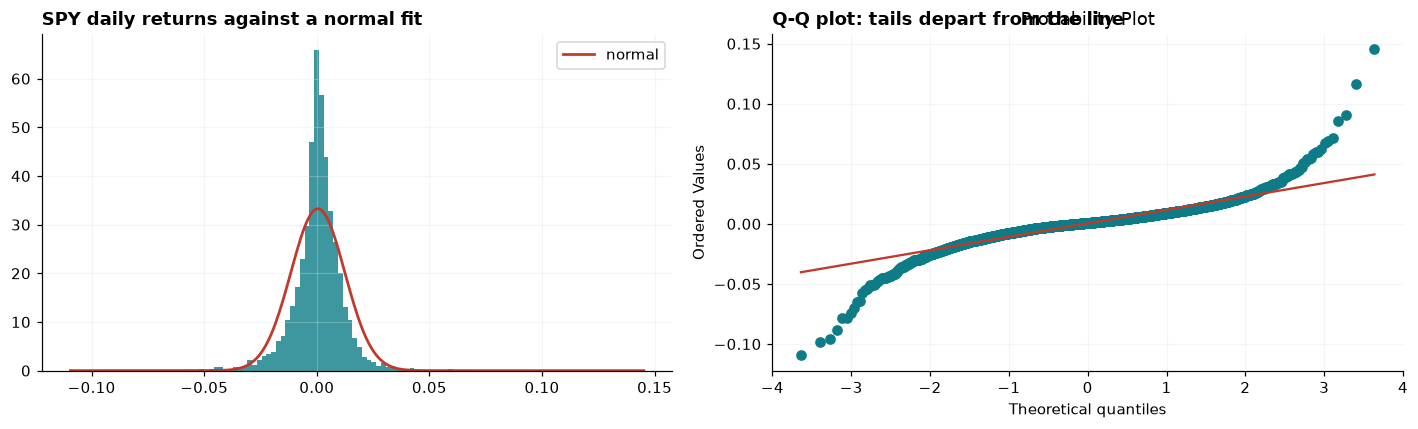

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(spy_returns, bins=120, color=TEAL, alpha=0.8, density=True)
grid = np.linspace(spy_returns.min(), spy_returns.max(), 300)
axes[0].plot(grid, stats.norm.pdf(grid, spy_returns.mean(), spy_returns.std()),
             color=RED, lw=1.8, label="normal")
axes[0].set_title("SPY daily returns against a normal fit", loc="left", fontweight="bold")
axes[0].legend()

stats.probplot(spy_returns, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot: tails depart from the line", loc="left", fontweight="bold")
axes[1].get_lines()[0].set_color(TEAL)
axes[1].get_lines()[1].set_color(RED)

save("01_fat_tails")
plt.show()

### How Predictable are next day returns?

Return autocorrelation should sit close to zero at every lag, mostly inside the
dashed band created. That is what an efficient market looks like, and it is why
next-day return prediction is hard.

Absolute returns tell the opposite story. Their autocorrelation is clearly
positive and decays slowly. **Volatility is predictable even when direction is
not.** That is the strongest signal in this data, and it is why rolling
volatility belongs in the feature set.


In [15]:
lags = range(1, 11)

autocorrelation = pd.DataFrame(
    {
        "returns": [spy_returns.autocorr(lag) for lag in lags],
        "absolute_returns": [spy_returns.abs().autocorr(lag) for lag in lags],
        "squared_returns": [(spy_returns ** 2).autocorr(lag) for lag in lags],
    },
    index=pd.Index(lags, name="lag"),
)

autocorrelation.round(4)

,returns,absolute_returns,squared_returns
lag,,,
1,-0.1027,0.3190,0.2605
2,-0.0195,0.4226,0.4601
3,0.0136,0.3458,0.2316
4,-0.0333,0.3591,0.2767
5,-0.0167,0.3688,0.3067
6,-0.0374,0.3609,0.2835
7,0.0518,0.3423,0.2859
8,-0.0410,0.3240,0.2210
9,0.0394,0.3307,0.2900


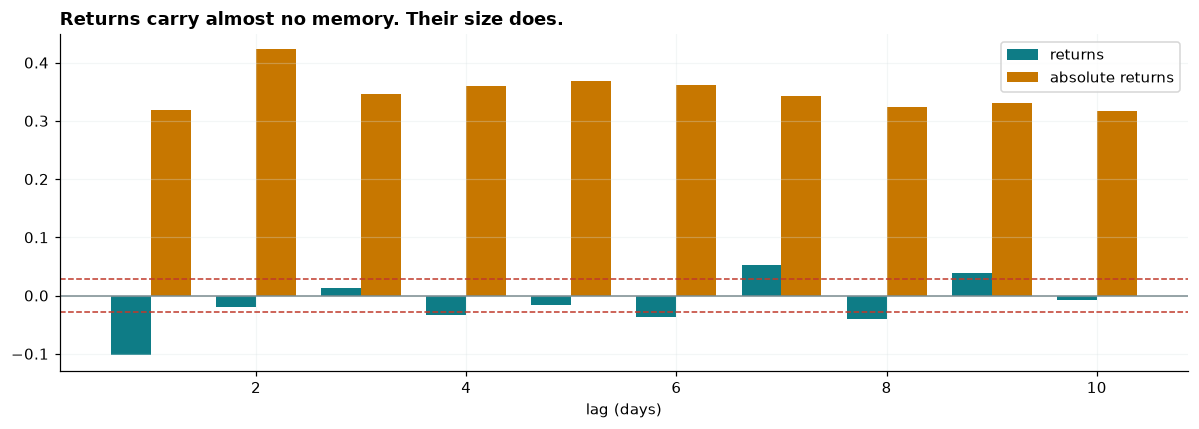

In [16]:
figure, axis = plt.subplots(figsize=(11, 4))
width = 0.38

axis.bar([x - width / 2 for x in lags], autocorrelation["returns"],
         width=width, color=TEAL, label="returns")
axis.bar([x + width / 2 for x in lags], autocorrelation["absolute_returns"],
         width=width, color=AMBER, label="absolute returns")
axis.axhline(0, color=GREY, lw=1)

# Rough significance band for white noise.
band = 1.96 / np.sqrt(len(spy_returns))
axis.axhline(band, color=RED, ls="--", lw=1)
axis.axhline(-band, color=RED, ls="--", lw=1)

axis.set_title("Returns carry almost no memory. Their size does.",
               loc="left", fontweight="bold")
axis.set_xlabel("lag (days)")
axis.legend()

save("01_autocorrelation")
plt.show()

### Volatility Clustering

It is a phenomenon in financial markets where large price movements tend to be followed by more large movements,
while small movements tend to be followed by more small movements.

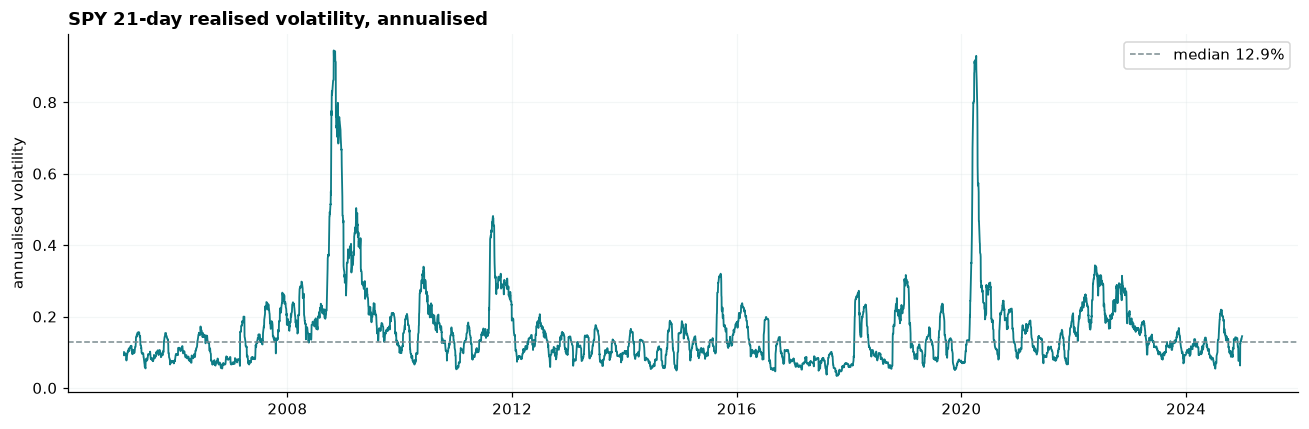

min 3.4%   median 12.9%   max 94.5%


In [18]:
realised_vol = spy_returns.rolling(21).std() * np.sqrt(252)

figure, axis = plt.subplots(figsize=(12, 4))
axis.plot(realised_vol.index, realised_vol, color=TEAL, lw=1.2)
axis.axhline(realised_vol.median(), color=GREY, ls="--", lw=1,
             label=f"median {realised_vol.median():.1%}")
axis.set_title("SPY 21-day realised volatility, annualised", loc="left", fontweight="bold")
axis.set_ylabel("annualised volatility")
axis.legend()

save("01_volatility_clustering")
plt.show()

print(f"min {realised_vol.min():.1%}   median {realised_vol.median():.1%}   "
      f"max {realised_vol.max():.1%}")

### Correlation across the universe

How much independent information the universe actually contains.

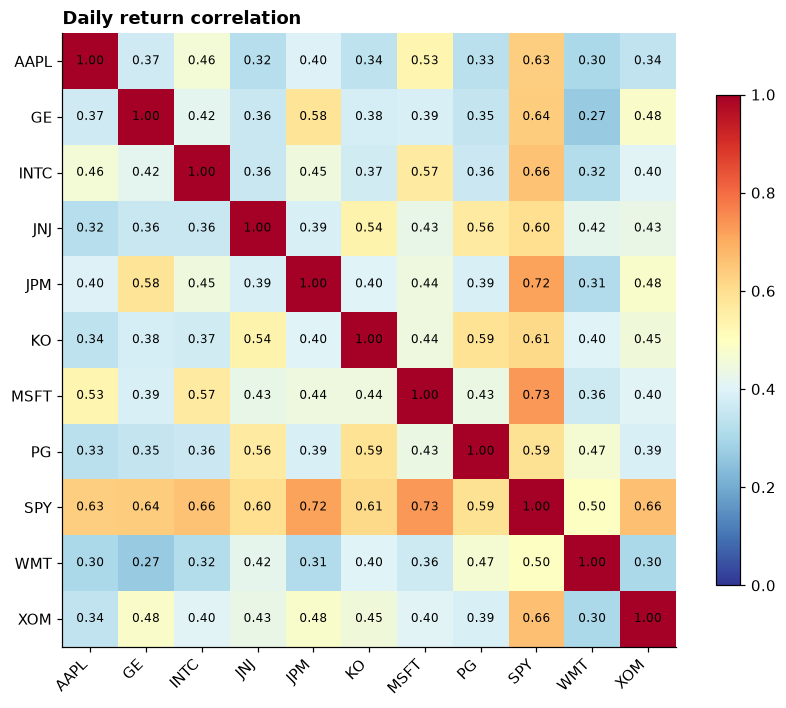

Mean pairwise correlation: 0.451
Range: 0.267 to 0.734


In [19]:
correlation = returns.corr()

figure, axis = plt.subplots(figsize=(8, 6.5))
image = axis.imshow(correlation, cmap="RdYlBu_r", vmin=0, vmax=1)

axis.set_xticks(range(len(correlation)))
axis.set_yticks(range(len(correlation)))
axis.set_xticklabels(correlation.columns, rotation=45, ha="right")
axis.set_yticklabels(correlation.index)
axis.grid(False)

for i in range(len(correlation)):
    for j in range(len(correlation)):
        axis.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

figure.colorbar(image, ax=axis, shrink=0.8)
axis.set_title("Daily return correlation", loc="left", fontweight="bold")

save("01_correlation")
plt.show()

upper = correlation.values[np.triu_indices_from(correlation, k=1)]
print(f"Mean pairwise correlation: {upper.mean():.3f}")
print(f"Range: {upper.min():.3f} to {upper.max():.3f}")

### Regimes

A model trained on one market environment can fail completely in another. Thism
splits the sample into periods and asks whether they look like the same problem.

In [20]:
regimes = {
    "pre-crisis": ("2005-01-01", "2007-09-30"),
    "crisis": ("2007-10-01", "2009-03-31"),
    "recovery": ("2009-04-01", "2020-01-31"),
    "covid": ("2020-02-01", "2020-04-30"),
    "post-covid": ("2020-05-01", "2024-12-31"),
}

rows = []
for name, (start, end) in regimes.items():
    window = returns.loc[start:end, "SPY"].dropna()
    if window.empty:
        continue

    rows.append({
        "regime": name,
        "days": len(window),
        "ann_return": (1 + window).prod() ** (252 / len(window)) - 1,
        "ann_vol": window.std() * np.sqrt(252),
        "worst_day": window.min(),
        "share_up": (window > 0).mean(),
    })

pd.DataFrame(rows).set_index("regime").round(3)

,days,ann_return,ann_vol,worst_day,share_up
regime,,,,,
pre-crisis,689,0.110,0.114,-0.039,0.559
crisis,378,-0.337,0.384,-0.098,0.495
recovery,2728,0.161,0.151,-0.065,0.558
covid,62,-0.324,0.596,-0.109,0.500
post-covid,1174,0.181,0.169,-0.058,0.550


In [21]:
price = bars["SPY"]["adj_close"]
half = len(price) // 2

comparison = pd.DataFrame({
    "first half": {
        "price mean": price.iloc[:half].mean(),
        "price std": price.iloc[:half].std(),
        "return mean": spy_returns.iloc[:half].mean(),
        "return std": spy_returns.iloc[:half].std(),
    },
    "second half": {
        "price mean": price.iloc[half:].mean(),
        "price std": price.iloc[half:].std(),
        "return mean": spy_returns.iloc[half:].mean(),
        "return std": spy_returns.iloc[half:].std(),
    },
})

comparison.round(5)

,first half,second half
price mean,101.26128,307.74721
price std,25.49309,113.50853
return mean,0.00038,0.00055
return std,0.01282,0.01110


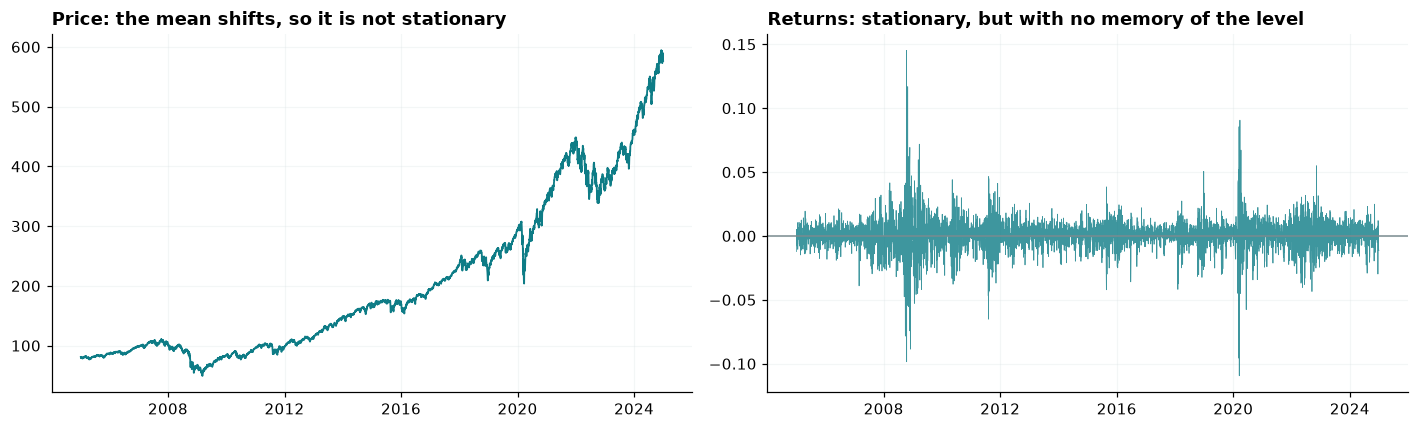

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(price.index, price, color=TEAL, lw=1.2)
axes[0].set_title("Price: the mean shifts, so it is not stationary",
                  loc="left", fontweight="bold")

axes[1].plot(spy_returns.index, spy_returns, color=TEAL, lw=0.5, alpha=0.8)
axes[1].axhline(0, color=GREY, lw=1)
axes[1].set_title("Returns: stationary, but with no memory of the level",
                  loc="left", fontweight="bold")

save("01_stationarity")
plt.show()

### Cross-source check

One source agreeing with itself proves nothing. This pulls the benchmark from a
second, independent provider and compares them.

Needs a network connection. Skip it if offline.

In [23]:
CHECK_TICKER = "SPY"

try:
    from pandas_datareader import data as web

    other = web.DataReader(
        f"{CHECK_TICKER}.US", "stooq",
        bars[CHECK_TICKER].index[0], bars[CHECK_TICKER].index[-1],
    ).sort_index()

    mine = bars[CHECK_TICKER]["adj_close"]
    theirs = other["Close"]

    aligned = pd.DataFrame({"yfinance": mine, "stooq": theirs}).dropna()
    aligned["ratio"] = aligned["yfinance"] / aligned["stooq"]
    aligned["return_gap"] = (
        aligned["yfinance"].pct_change() - aligned["stooq"].pct_change()
    ).abs()

    print(f"Overlapping days: {len(aligned):,}")
    print(f"Median daily return difference: {aligned['return_gap'].median():.2e}")
    print(f"Days differing by more than 10 bps: {(aligned['return_gap'] > 0.001).sum()}")

except Exception as exc:
    print(f"Cross-source check skipped: {exc}")

Cross-source check skipped: data_source='stooq' is not implemented
